## PCA and Text Analysis

This assignment involves processing real e-mails, some of which are scams. 

(Fair warning: Some of these scam e-mails have offensive content. If you start reading the e-mail text or the token data, you might read something offensive. If that's a problem, feel free to e-mail us, and we can talk about it and discuss how to proceed with alternative tasks.)

**Q1.**

**Tokens**: The individual words or symbols that create text data like emails. Natural Language Processing is primarily about analyzing the frequency and co-occurrence of tokens.

We aggregated all the emails into a single vector, and removed the punctuation and very common words (e.g. "the"). Run the below code chunk to open it, and use the Counter class to look at the most common words:

In [ ]:
# Your Phase 1 solution to the problem goes here.
import pickle
import matplotlib.pyplot as plt  
import seaborn as sns          
import numpy as np     
import pandas as pd        
from sklearn.decomposition import PCA    

with open('data/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)
    
from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()

Plot a histogram of the occurrences of tokens. 
What do you notice about the frequency of occurrence of different tokens? How does it look?

**Q2.** 

Load `Phishing_clean.parquet`. This is the text from the e-mails broken into the most common 2,711 tokens and one-hot-encoded as features/covariates. So each row is an e-mail, the `Email Type` takes the value 1 if it's a scam and 0 otherwise, and every other column is a word or symbol that occurs in at least 15 e-mails.

1. Perform an 80/20 train-test split of the data.
2. Run a regression of $y$ on the one-hot-encoded emails. What is the $R^2$ on the test set? On the training set?
3. What words have the largest coefficients in absolute value and most strongly influence predictions? 

**Q3.** 

Take the matrix of one-hot-encoded tokens (the data, less the outcome variable, `Email Type`) and perform a principal components analysis decomposition with two components. Plot the first two principal components in a scatter plot, and hue the points by whether they are a phishing scam or not. Do you notice any patterns?

**Q4.**

Run a linear regression of $y$ on the first 2,610 principal components of $X$. What is the $R^2$ on the training and test sets?
How does this performance compare to the linear regression?

**Q5.**

Explain briefly in your own words what the advantage is in using the principal components to run this high-dimensional regression, rather than the original data.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Aiden Zhu

**Date:** 10/21/2026

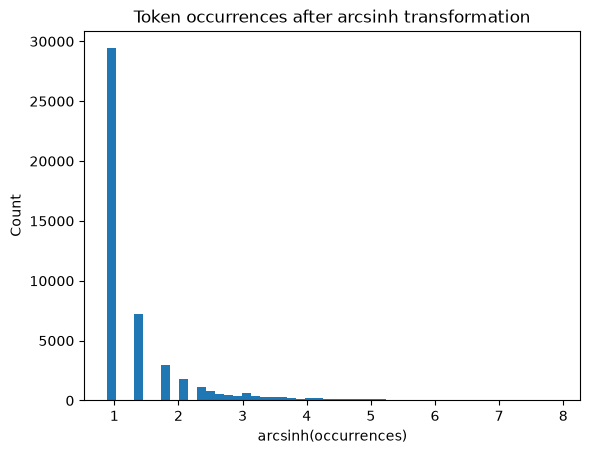

Train R-squared: 0.768
Valid R-squared: 0.6588
Sklearn: [0.011 0.009]


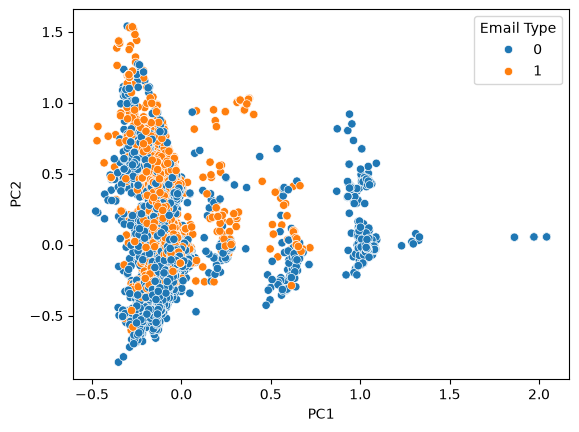

Train R-squared: 0.7673
Valid R-squared: 0.6597


In [ ]:
# Your Phase 1 solution to the problem goes here.
import pickle
import matplotlib.pyplot as plt  
import seaborn as sns          
import numpy as np     
import pandas as pd        
from sklearn.decomposition import PCA

with open('data/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)
    
from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()

occurances_arcsinh = np.arcsinh(pd.Series(token_count))
occurances_arcsinh.hist(bins=50, grid=False)
plt.title("Token occurrences after arcsinh transformation")
plt.xlabel("arcsinh(occurrences)")
plt.ylabel("Count")
plt.show()

from sklearn.model_selection import train_test_split  
from sklearn.linear_model import LinearRegression  

df = pd.read_parquet("data/Phishing_clean.parquet")  
y = df["Email Type"]
X = df.drop(columns="Email Type")
X_train, X_valid, y_train, y_valid = train_test_split(
    X, y, test_size=0.2, random_state=100
)
reg = LinearRegression().fit(X_train, y_train)
print("Train R-squared:", round(reg.score(X_train, y_train), 4))
print("Valid R-squared:", round(reg.score(X_valid, y_valid), 4))
coefs = pd.Series(reg.coef_, index=X.columns)
print(coefs.abs().sort_values(ascending=False).head(10))   


X = df.drop(columns="Email Type")

pca_house = PCA(n_components=2).fit(X)
X_pca_sklearn = pca_house.transform(X)
print("Sklearn:", pca_house.explained_variance_ratio_.round(3))

df["PC1"] = X_pca_sklearn[:, 0]
df["PC2"] = X_pca_sklearn[:, 1]
ax = sns.scatterplot(data=df, x="PC1", y="PC2", hue="Email Type")
plt.show()

pca_house = PCA(n_components=2610).fit(X_train)      
X_train_pca = pca_house.transform(X_train)           
X_valid_pca = pca_house.transform(X_valid)          

regression_pca = LinearRegression().fit(X_train_pca, y_train)                    
print("Train R-squared:", round(regression_pca.score(X_train_pca, y_train), 4))      
print("Valid R-squared:", round(regression_pca.score(X_valid_pca, y_valid), 4))  

1) I scaled the histogram using arcsinh because all of the data was grouped together and was hard to read because of that. In the original histogram, the data was almost unreadable. In the scaled histogram, the data is heavily skewed right, and we see that most tokens have an occurrence of 1 at almost 30,000, and then it drops off massively into only a couple thousands then hundreds occuring twice or more.

2) The R^2 on the training set is 0.768 and 0.659 for the test set. The words with the largest correlation in absolute value are "background-image:", "localized", and "helvetica". I don't really know what these words mean, but they most influence predictions for scam emails. These words don't really seem like what would be included in the text in an email, so it may be another factor that the model is predicted besides email content.

3) Yes, there are definitely some noticeable patterns in the scatterplot. We see that most of the points are grouped together vertically, with the most sitting around -0.5 to 0 for the PC1 x-axis. Then we see groups around 0.5, 1, and 3 outlier points at 2.0. There are no scam emails after PC1 of 0.8. Regarding the y axis, it looks like the scam emails are more variable compared to non-scam emails across the y-axis. Around PC1, of -0.5 to 0, all of the non-scam emails and scam emails overlap with each other, so they are not very distinguishable on the scatterplot. 

4) There is essentially no difference when running the linear regression of Y compared to the original. The Train R^2 value went from 0.768 to 0.7673 and the Valid R^2 went from 0.6588 to 0.6597. I think these differences are so small that it doesn't really even matter. 

5) Using principal components analysis is useful because it allows variation in the data to be preserved while removing overlapping information that may make predictions worse. Additionally, in question 4, we took away 101 variables, and this slightly lowered training data while increasing the testing data, which shows that the training data was probably just noise in the data.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** 8d91e5d62e46143a0cc47a35bb3ef9fb1e51c434
- **AI tool and model used:** Claude Opus 5.5

### *Prompts used

1. Here is my Phase 1 code. Revise the code so each question is in its own cell with its output showing directly under it. Fix anything incorrect or inconsistent, and keep my code that doesn't need changing. For every change, give a bulleted list and why you changed it.
2. Here is my phase 1 written responses. point out any mistakes in my answers from the code in a bulleted list, why it is wrong, and what I should do to change it.


### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. Add a raw histogram before the arcsinh one (Q1). Rubric items 1.1 and 1.2 grade a “histogram of token occurrences”, and your answer refers to “the original histogram”, which your code doesn’t plot. Add:
python
  pd.Series(token_count).hist(bins=50, grid=False)
  plt.title("Token occurrences")
  plt.xlabel("Occurrences per token")
  plt.ylabel("Count")
  plt.show()
Rename occurances_arcsinh to occurrences_arcsinh (Q1). It’s a spelling error, in both places it appears.
Add print(coefs.sort_values()) after the top-10 line (Q2). Rubric item 2.6 asks which words “most strongly influence predictions”. Your current output shows absolute values, which hide whether each word pushes toward scam (positive) or legitimate (negative). You need the direction to back up your written answer.
Delete the second X = df.drop(columns="Email Type") (Q3). It’s identical to the line in your Q2 code, so it’s redundant.

2. 1) Two fixes. “most tokens have an occurrence of 1 at almost 30,000” mixes up the count of tokens with the number of occurrences, and there were grammar and spelling slips (“a couple thousands”, “occuring”).

2) Three fixes. “Correlation” should be “coefficients”, which is what the question asks about. Which way the words push isn’t verified yet, so fill in the bracket after checking the print(coefs.sort_values()) output. And rubric 2.6 grades the words’ influence, so “I don’t really know what these words mean” loses points; explain them instead.

3) Two fixes. “Scam emails are more variable” isn’t accurate: both classes span a similar range, and scam emails sit higher. “All” also overstates the overlap.

4) No changes needed.

5) Three fixes. The conclusion was backwards: it’s the dropped components that were noise, not the training data. “Training data” and “testing data” should be the R² values. And PCA combines overlapping information into new components; it doesn’t remove it.


### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | modify | Most of the changes weren't very helpful, but I took them nonetheless. |
| 2 | modify | It helped me answer some questions and fix my misinterpretations of some code |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

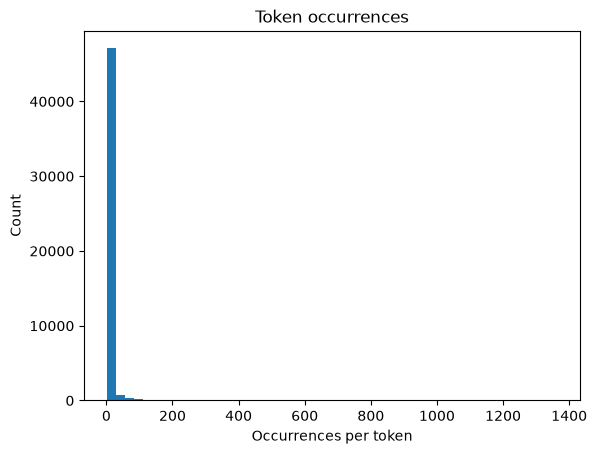

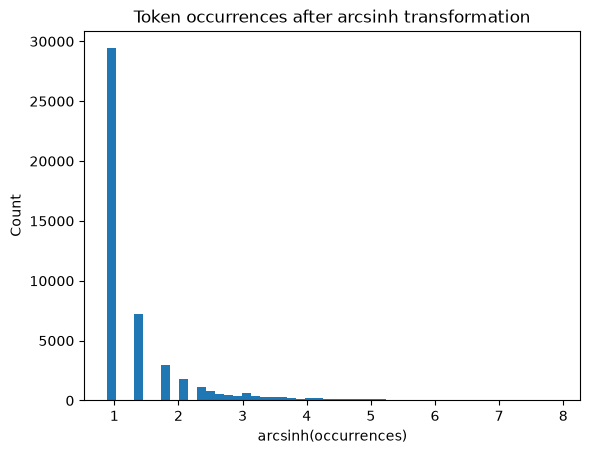

: 

In [1]:
# Your Phase 2 solution to the problem goes here.
# Q1
import pickle
import matplotlib.pyplot as plt  
import seaborn as sns          
import numpy as np     
import pandas as pd        
from sklearn.decomposition import PCA

with open('data/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)
    
from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()

pd.Series(token_count).hist(bins=50, grid=False)
plt.title("Token occurrences")
plt.xlabel("Occurrences per token")
plt.ylabel("Count")
plt.show()

occurrences_arcsinh = np.arcsinh(pd.Series(token_count))
occurrences_arcsinh.hist(bins=50, grid=False)
plt.title("Token occurrences after arcsinh transformation")
plt.xlabel("arcsinh(occurrences)")
plt.ylabel("Count")
plt.show()

# Q2
from sklearn.model_selection import train_test_split  
from sklearn.linear_model import LinearRegression  

df = pd.read_parquet("data/Phishing_clean.parquet")  
y = df["Email Type"]
X = df.drop(columns="Email Type")
X_train, X_valid, y_train, y_valid = train_test_split(
    X, y, test_size=0.2, random_state=100
)
reg = LinearRegression().fit(X_train, y_train)
print("Train R-squared:", round(reg.score(X_train, y_train), 4))
print("Valid R-squared:", round(reg.score(X_valid, y_valid), 4))
coefs = pd.Series(reg.coef_, index=X.columns)
print(coefs.abs().sort_values(ascending=False).head(10))   
print(coefs.sort_values())

# Q3
pca_house = PCA(n_components=2).fit(X)
X_pca_sklearn = pca_house.transform(X)
print("Sklearn:", pca_house.explained_variance_ratio_.round(3))

df["PC1"] = X_pca_sklearn[:, 0]
df["PC2"] = X_pca_sklearn[:, 1]
ax = sns.scatterplot(data=df, x="PC1", y="PC2", hue="Email Type")
plt.show()

# Q4
pca_house = PCA(n_components=2610).fit(X_train)      
X_train_pca = pca_house.transform(X_train)           
X_valid_pca = pca_house.transform(X_valid)          

regression_pca = LinearRegression().fit(X_train_pca, y_train)                    
print("Train R-squared:", round(regression_pca.score(X_train_pca, y_train), 4))      
print("Valid R-squared:", round(regression_pca.score(X_valid_pca, y_valid), 4))

1) I scaled the histogram using arcsinh because all of the data was grouped together and was hard to read because of that. In the original histogram, the data was almost unreadable. In the scaled histogram, the data is heavily skewed right, and we see that almost 30,000 tokens occur only once, and then it drops off massively into only a few thousand then hundreds of tokens occurring twice or more.

2) The R^2 on the training set is 0.768 and 0.659 for the test set. The words with the largest coefficients in absolute value are “background-image:”, “localized”, and “helvetica”. These words most influence predictions toward scam emails. “background-image:” and “helvetica” are pieces of HTML formatting code rather than words people would actually write, so the model may be predicting based on how an email is formatted, not just its content.

3) There are definitely some noticeable patterns in the scatterplot. We see that most of the points are grouped together vertically, with the most sitting around -0.5 to 0 for the PC1 x-axis. Then we see groups around 0.5, 1, and 3 outlier points at 2.0. There are no scam emails after PC1 of 0.8. Regarding the y axis, scam emails tend to have higher PC2 values than non-scam emails. Around PC1 of -0.5 to 0, most of the non-scam and scam emails overlap with each other, so they are not very distinguishable on the scatterplot.

4) There is essentially no difference when running the linear regression of Y compared to the original. The Train R^2 value went from 0.768 to 0.7673 and the Valid R^2 went from 0.6588 to 0.6597. I think these differences are so small that it doesn’t really even matter.

5) Using principal components analysis is useful because it allows variation in the data to be preserved while combining overlapping information that may make predictions worse. Additionally, in question 4, we took away 101 components, and this slightly lowered the training R^2 while increasing the test R^2, which shows that the components we removed were probably just noise in the data.

### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]

This time, the AI assistance wasn't very helpful for the code but was more helpful with my written responses. For my code, it only fixed some spelling issues and unnecessary outputs because I didn't want it to make too much of a stretch and give it that much liberty on my code. But for the writing segment, it helped me when I misenterpreted some information and why it happened. The lectures in class and content on the slides are very dense, so sometimes learning it can be a little challenging. Therefore, the AI is there to help teach me what I didn't understand initially. In the end, the AI did help me probably recover some points I missed and helped me understand some concepts at a deeper level. I don't have any concerns about the AI for this specific assignment, and it was helpful to check against the rubric to see what I missed.